# CSCI 3003 - Data Visualization

## Lab 5: Comparing Groups with Seaborn

**Name:** Steve Tatsiguia  
**Date:** 2026-09-24  
**Version:** Student notebook

> Add your name and date before submitting.


## Purpose and learning objectives

A graph of one distribution can answer *What values are common?* Comparing distributions adds a second question: *How do the groups differ?* This lab introduces Seaborn as a concise plotting interface that works naturally with long-form pandas data.

By the end, you should be able to:

- Connect one row and one column in a long-form DataFrame to Seaborn's `data`, `x`, `y`, and `hue` arguments.
- Compare quantitative distributions with grouped histograms and box plots.
- Use category order, color, and separate panels to make comparisons easier to read.
- Explain what a box plot shows without treating every difference as proof of a population difference.
- Recognize KDE and violin plots and identify cautions when interpreting their smoothed shapes.
- Choose and critique a grouped-distribution display based on the analytical question.


## I. Setup and data

This lab continues with the simplified Palmer Penguins dataset from Lab 4. Keeping the same data lets us concentrate on new comparison methods.

Seaborn is installed separately as part of the course environment. Routine notebooks should import it, not reinstall it.

The configured Jupyter working directory is `01-labs/`, so the relative path is `Path("penguins.csv")` even though this notebook is stored in the `Lab5` folder.


In [24]:
from pathlib import Path

import matplotlib.pyplot as plt
import pandas as pd
import seaborn as sns

In [25]:
Path.cwd()

WindowsPath('c:/Users/steve/OneDrive/Documents/CSCI-3003-Data-Visualization/01-labs')

In [26]:
penguin_file = Path("penguins.csv")
penguin_file.exists()

True

In [27]:
penguins = pd.read_csv(penguin_file)
penguins.head()

,species,island,bill_length_mm,bill_depth_mm,flipper_length_mm,body_mass_g,sex,year
0,Adelie,Torgersen,39.1,18.7,181.0,3750.0,male,2007
1,Adelie,Torgersen,39.5,17.4,186.0,3800.0,female,2007
2,Adelie,Torgersen,40.3,18.0,195.0,3250.0,female,2007
3,Adelie,Torgersen,NaN,NaN,NaN,NaN,NaN,2007
4,Adelie,Torgersen,36.7,19.3,193.0,3450.0,female,2007


**Question 1:** What does one row represent? Does this table already have a useful long-form structure for comparing `body_mass_g` across `species`?

**Answer:** Each row represents one penguin. Yes, because each penguin has its own row, with its species and body mass


## II. Prepare only the variables needed

Lab 3 showed that a plotting workflow often begins by selecting columns, filtering rows, and addressing missing values. The next chain keeps the two variables required for the first comparison and removes rows missing either value.

`.dropna(subset=[...])` checks only the named columns. This is more deliberate than removing a row because some unrelated variable is missing.


In [28]:
mass_by_species = penguins[["species", "body_mass_g"]].dropna(
    subset=["species", "body_mass_g"]
)

mass_by_species.head()

,species,body_mass_g
0,Adelie,3750.0
1,Adelie,3800.0
2,Adelie,3250.0
4,Adelie,3450.0
5,Adelie,3650.0


**Practice:** Practice finding median body mass by species using `.groupby` and `.agg`.

In [29]:
median_mass = (
    mass_by_species
    .groupby("species")
    .agg(median_body_mass=("body_mass_g", "median"))
)

median_mass

,median_body_mass
species,
Adelie,3700.0
Chinstrap,3700.0
Gentoo,5000.0


**Check your work:**

In [30]:
(
    mass_by_species.groupby("species")
    .agg(
        penguin_count=("body_mass_g", "size"),
        median_body_mass_g=("body_mass_g", "median"),
    )
    .reset_index()
)

,species,penguin_count,median_body_mass_g
0,Adelie,151,3700.0
1,Chinstrap,68,3700.0
2,Gentoo,123,5000.0


**Question 2:** Prepare a DataFrame named `flipper_by_island` containing only `island` and `flipper_length_mm`. Remove rows missing either variable. Then create a grouped summary with the observation count and median flipper length for each island.


In [31]:
# Create flipper_by_island, then display its grouped summary.

flipper_by_island = penguins[["island", "flipper_length_mm"]].dropna(
    subset=["island", "flipper_length_mm"]
)

(
    flipper_by_island.groupby("island")
    .agg(
        penguin_count=("flipper_length_mm", "size"),
        median_flipper_length_mm=("flipper_length_mm", "median")
    )
    .reset_index()
)

,island,penguin_count,median_flipper_length_mm
0,Biscoe,167,214.0
1,Dream,124,193.0
2,Torgersen,51,191.0


## III. Map DataFrame columns to a Seaborn plot

Seaborn functions accept a DataFrame through `data`. Column names then identify visual roles:

- `x` places a quantitative variable on the horizontal axis.
- `hue` uses color to distinguish groups.
- `bins` controls the histogram intervals, as in Matplotlib.
- `element="step"` draws outlines so overlapping groups hide less of one another.

Seaborn creates the marks, but Matplotlib's Axes methods still supply the title and labels.


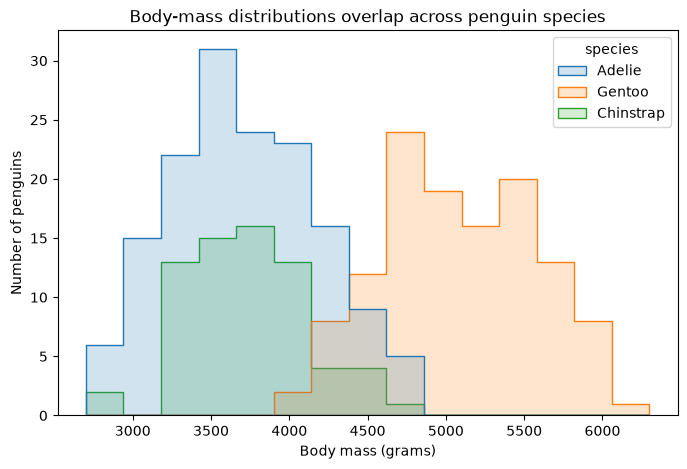

In [32]:
fig, ax = plt.subplots(figsize=(8, 5))

sns.histplot(
    data=mass_by_species,
    x="body_mass_g",
    hue="species",
    bins=15,
    element="step",
    fill=True,
    alpha=0.2,
    ax=ax,
)

ax.set_title("Body-mass distributions overlap across penguin species")
ax.set_xlabel("Body mass (grams)")
ax.set_ylabel("Number of penguins")
plt.show()

**Question 3:** For the graph above, identify the DataFrame, the quantitative variable, the grouping variable, and the role of color. What does one histogram interval represent?

**Answer:** The DataFrame is mass_by_species. The quantitative variable is body_mass_g, and the grouping variable is species. The colors help us tell the different penguin species apart. Each histogram interval represents a range of body masses and shows how many penguins fall within that range.


**Question 4:** Describe one comparison the graph supports and one feature that is difficult to judge because the distributions overlap. Use cautious language: these are recorded penguins, not a random sample of every penguin in each species.

**Answer:** The graph shows that Gentoo penguins tend to be heavier than Adelie and Chinstrap penguins in this dataset. However, it is difficult to see the exact number of penguins in some weight ranges because the histograms overlap. These results only describe the penguins in this dataset, not all penguins.


### Try a different grouping variable

Use the `flipper_by_island` table from Question 2. A complete Seaborn call must name the prepared DataFrame and map its columns to `x` and `hue`.

**Question 5:** Create an outlined grouped histogram comparing `flipper_length_mm` across `island`. Try at least two reasonable values of `bins`, keep the clearer version, and explain your choice.

**Answer:**


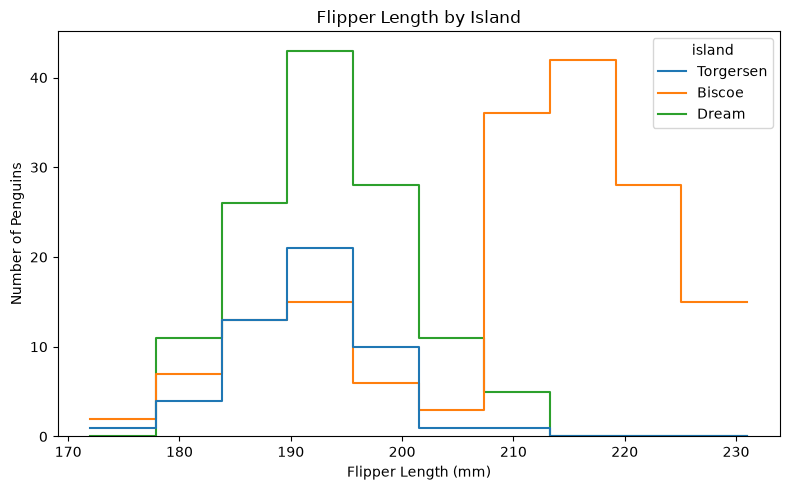

In [33]:
# Create the grouped histogram and retain your preferred bin choice.

# Try two different bin sizes
fig, ax = plt.subplots(figsize=(8, 5))

sns.histplot(
    data=flipper_by_island,
    x="flipper_length_mm",
    hue="island",
    bins=10,
    element="step",
    fill=False,
    ax=ax
)

ax.set_title("Flipper Length by Island")
ax.set_xlabel("Flipper Length (mm)")
ax.set_ylabel("Number of Penguins")

plt.tight_layout()
plt.show()

## IV. Use box plots for compact group comparisons

A box plot summarizes each group rather than showing every histogram interval.

- The line inside the box is the median.
- The box extends from the first quartile to the third quartile; this is the middle 50% of the values.
- The whiskers extend to the most extreme values within 1.5 times the interquartile range from the box.
- Points beyond the whiskers are plotted individually. They are unusual by this rule, but they are not automatically errors.

In `sns.boxplot()`, `x` can hold the group and `y` the quantitative measurement.


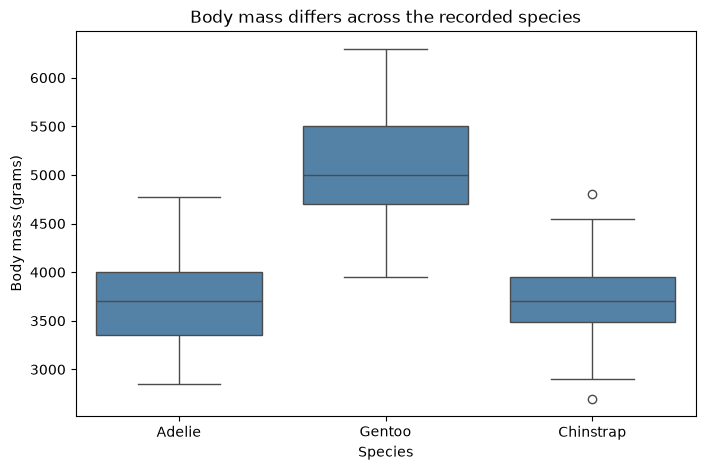

In [34]:
fig, ax = plt.subplots(figsize=(8, 5))

sns.boxplot(
    data=mass_by_species,
    x="species",
    y="body_mass_g",
    color="steelblue",
    ax=ax,
)

ax.set_title("Body mass differs across the recorded species")
ax.set_xlabel("Species")
ax.set_ylabel("Body mass (grams)")
plt.show()

**Question 6:** Which species has the highest median body mass? Which pair of species has the greatest overlap in their middle 50%? Explain how you read both answers from the graph.

**Answer:** Gentoo penguins have the highest median body mass at 5,000 grams. Adelie and Chinstrap have the greatest overlap in their middle 50%. I can tell because Gentoo has the highest median line, while the boxes for Adelie and Chinstrap overlap the most.


**Question 7:** A student says, “Every point beyond a whisker is bad data and should be deleted.” Explain why that conclusion is not justified by a box plot alone.

**Answer:** A point outside the whiskers is an outlier, but that does not mean it is bad data. It could just be a penguin that weighs more or less than the others. We should check the data before deciding to delete it.


## V. Control category order deliberately

Seaborn accepts an `order` list for categorical axes. A useful order should support the question. The next code computes the species order from smallest to largest median body mass instead of typing an order based on visual guesswork.


In [35]:
species_mass_order = (
    mass_by_species.groupby("species")["body_mass_g"]
    .median()
    .sort_values()
    .index.tolist()
)

species_mass_order

['Adelie', 'Chinstrap', 'Gentoo']

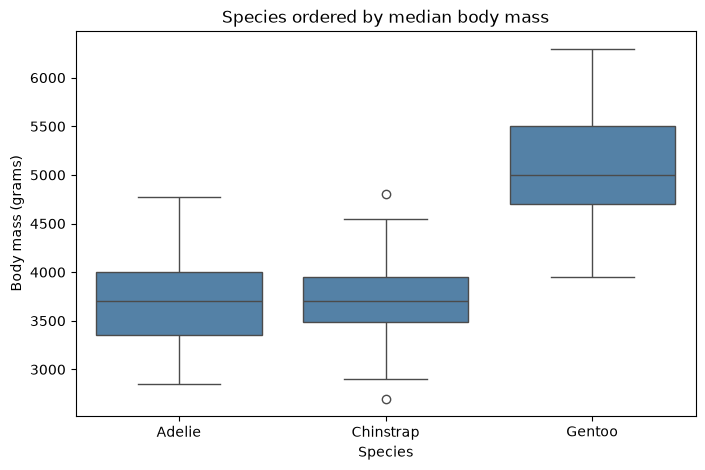

In [36]:
fig, ax = plt.subplots(figsize=(8, 5))

sns.boxplot(
    data=mass_by_species,
    x="species",
    y="body_mass_g",
    order=species_mass_order,
    color="steelblue",
    ax=ax,
)

ax.set_title("Species ordered by median body mass")
ax.set_xlabel("Species")
ax.set_ylabel("Body mass (grams)")
plt.show()

**Question 8:** Create a box plot comparing `flipper_length_mm` across islands. Compute the island order from shortest to longest median flipper length, use that order in the plot, and label the graph clearly.


In [37]:
# Compute island_flipper_order, then create the ordered box plot.

island_flipper_order = (
    flipper_by_island
    .groupby("island")["flipper_length_mm"]
    .median()
    .sort_values()
    .index.tolist()
)

island_flipper_order

['Torgersen', 'Dream', 'Biscoe']

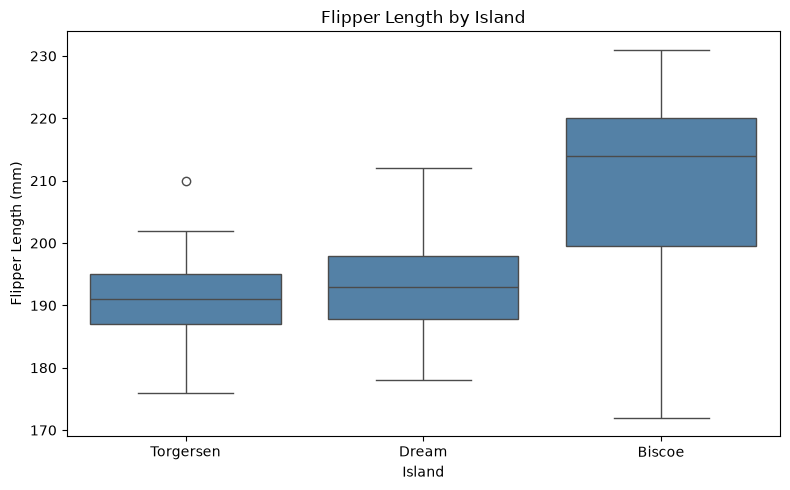

In [38]:
fig, ax = plt.subplots(figsize=(8, 5))

sns.boxplot(
    data=flipper_by_island,
    x="island",
    y="flipper_length_mm",
    order=island_flipper_order,
    color="steelblue",
    ax=ax
)

ax.set_title("Flipper Length by Island")
ax.set_xlabel("Island")
ax.set_ylabel("Flipper Length (mm)")

plt.tight_layout()
plt.show()

## VI. Decide whether color helps

Color is useful when it adds a meaningful comparison. Repeating the x-axis variable with `hue` usually adds color without adding information. In the next graph, `species` is on the x-axis and `sex` supplies a second grouping variable.

`palette="colorblind"` requests a restrained palette designed to remain distinguishable for many viewers with common forms of color-vision deficiency.


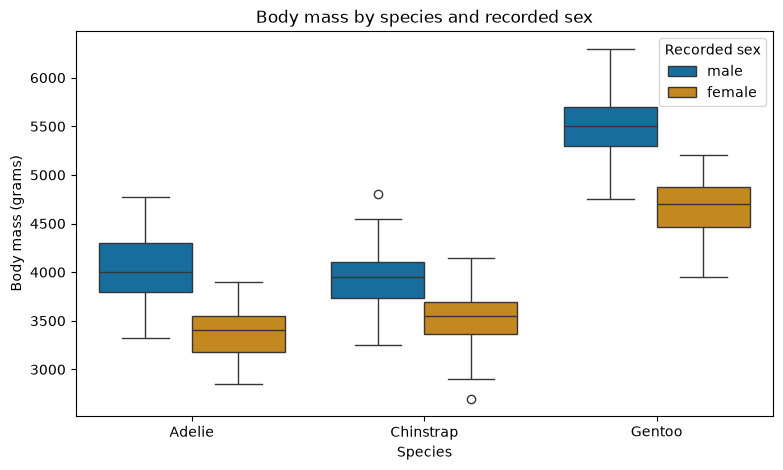

In [39]:
mass_by_species_and_sex = penguins.loc[:, ["species", "sex", "body_mass_g"]].dropna(
    subset=["species", "sex", "body_mass_g"]
)

fig, ax = plt.subplots(figsize=(9, 5))

sns.boxplot(
    data=mass_by_species_and_sex,
    x="species",
    y="body_mass_g",
    hue="sex",
    order=species_mass_order,
    palette="colorblind",
    ax=ax,
)

ax.set_title("Body mass by species and recorded sex")
ax.set_xlabel("Species")
ax.set_ylabel("Body mass (grams)")
ax.legend(title="Recorded sex")
plt.show()

**Question 9:** What comparison does `hue="sex"` add? Identify one pattern visible across species and one limitation that prevents a strong generalization.

**Answer:** Using hue="sex" lets us compare male and female penguins within each species using different colors. The graph shows that male penguins tend to have a higher body mass than females across all three species. One limitation is that some penguins have missing data, and this dataset does not represent every penguin in the world.


## VII. Separate crowded comparisons with facets

When colors overlap or a graph becomes crowded, small multiples place groups in separate, consistently scaled panels. Seaborn's figure-level `displot()` can create these panels with `col`.

Unlike an axes-level function such as `sns.histplot()`, `sns.displot()` creates and manages its own Figure. Do not create `fig, ax = plt.subplots()` first. The returned `FacetGrid` is stored below as `mass_grid`.


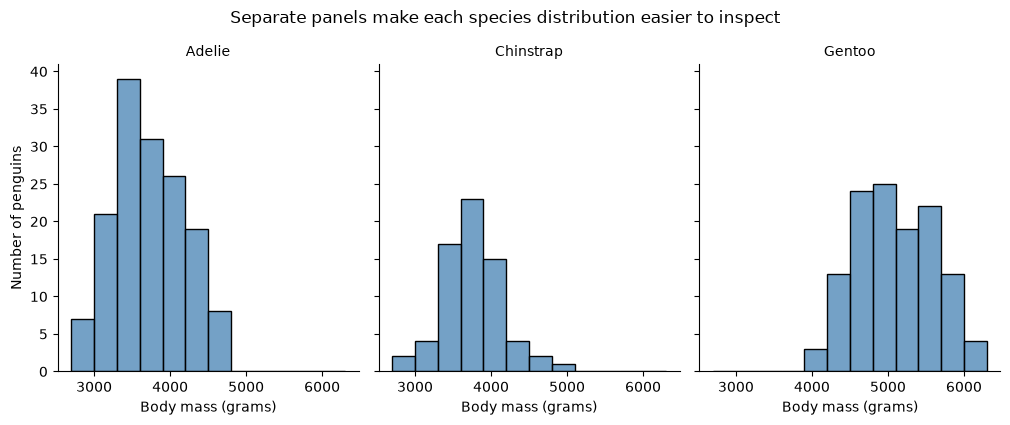

In [40]:
mass_grid = sns.displot(
    data=mass_by_species,
    x="body_mass_g",
    col="species",
    col_order=species_mass_order,
    bins=12,
    color="steelblue",
    height=4,
    aspect=0.85,
)

mass_grid.set_axis_labels("Body mass (grams)", "Number of penguins")
mass_grid.set_titles("{col_name}")
mass_grid.figure.suptitle(
    "Separate panels make each species distribution easier to inspect",
    y=1.05,
)
plt.show()

**Question 10:** Compare the faceted histograms with the overlaid histograms in Section III. What becomes easier to see? What direct comparison becomes harder when the groups are separated?

**Answer:** The separate histograms make it easier to see the body mass distribution of each penguin species without the bars overlapping. However, it is harder to compare how much the species overlap in body mass because they are shown in different panels.


**Question 11:** Use `sns.displot()` to create one histogram panel per island for `flipper_length_mm`. Use the same bins and axis limits across panels, label the axes, and give the complete Figure a descriptive title.


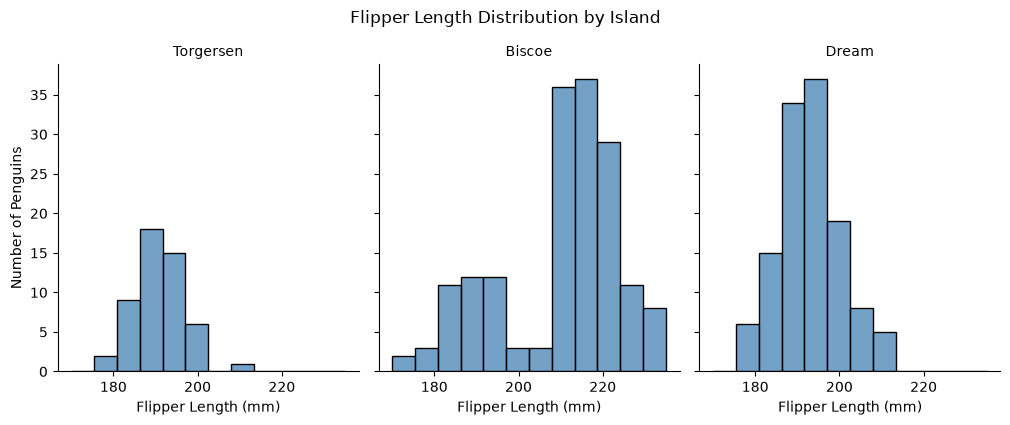

In [41]:
# Create the faceted flipper-length histograms.

flipper_grid = sns.displot(
    data=flipper_by_island,
    x="flipper_length_mm",
    col="island",
    bins=12,
    binrange=(170, 235),
    color="steelblue",
    height=4,
    aspect=0.85,
    facet_kws={"sharex": True, "sharey": True}
)

flipper_grid.set_axis_labels(
    "Flipper Length (mm)",
    "Number of Penguins"
)

flipper_grid.set_titles("{col_name}")

flipper_grid.figure.suptitle(
    "Flipper Length Distribution by Island",
    y=1.05
)

plt.show()

## VIII. Recognize KDE and violin plots

A **kernel density estimate (KDE)** represents a distribution with a smooth curve. The curve's height is density, not a number of observations. Its shape depends on a smoothing choice, and it can extend into impossible or unsupported values. A KDE is therefore an estimate—not a traced outline of the raw data.

A **violin plot** mirrors a KDE around a center line and can include a compact box-plot summary. It emphasizes shape, but readers may find its width less intuitive than a box plot.

These displays are introduced for interpretation and critique. You are not required to use either in the final investigation.


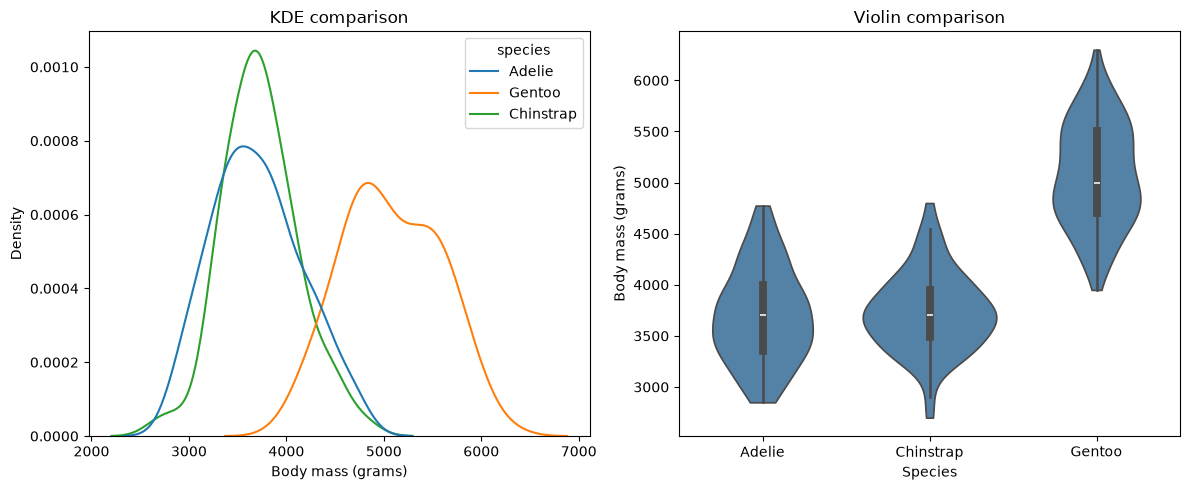

In [42]:
fig, axes = plt.subplots(nrows=1, ncols=2, figsize=(12, 5))

sns.kdeplot(
    data=mass_by_species,
    x="body_mass_g",
    hue="species",
    common_norm=False,
    ax=axes[0],
)
axes[0].set_title("KDE comparison")
axes[0].set_xlabel("Body mass (grams)")

sns.violinplot(
    data=mass_by_species,
    x="species",
    y="body_mass_g",
    order=species_mass_order,
    color="steelblue",
    inner="box",
    cut=0,
    ax=axes[1],
)
axes[1].set_title("Violin comparison")
axes[1].set_xlabel("Species")
axes[1].set_ylabel("Body mass (grams)")

plt.tight_layout()
plt.show()

**Question 12:** What does the width of a violin represent? Why might a box plot be the clearer choice for an audience unfamiliar with density?

**Answer:** The width of a violin shows where the data is more concentrated. A wider section means more penguins have body masses around that value. A box plot might be easier to understand because it clearly shows the median, middle 50%, and outliers without needing to understand density.


## IX. Critique the display, not just the code

The following code runs, but its choices make comparison unnecessarily difficult.


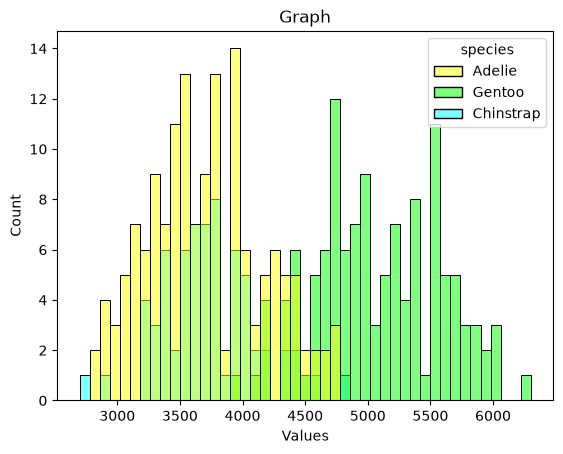

In [43]:
sns.histplot(
    data=penguins,
    x="body_mass_g",
    hue="species",
    bins=45,
    multiple="layer",
    palette=["yellow", "lime", "cyan"],
)
plt.title("Graph")
plt.xlabel("Values")
plt.show()

**Question 13:** Identify at least four weaknesses or risks in this display. Then revise it as either a clearer grouped histogram, an ordered box plot, or faceted histograms. Explain why your selected form fits the comparison.

**Answer:** The graph has too many bins, which makes it look crowded. The colors are too bright, and the bars overlap, making it hard to compare the species. The title and x-axis label are also not descriptive enough. I chose separate histograms because they make it easier to see the body mass distribution of each species without overlapping bars.


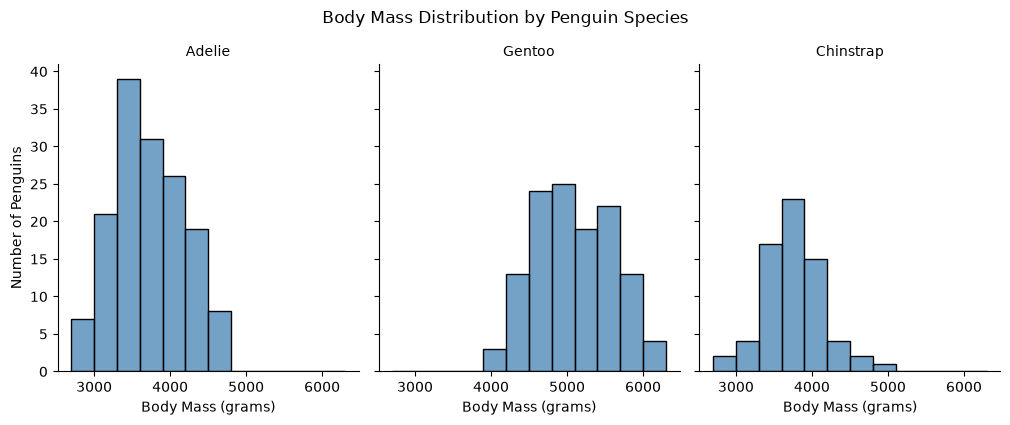

In [44]:
# Create and label your revision.

mass_grid = sns.displot(
    data=mass_by_species,
    x="body_mass_g",
    col="species",
    bins=12,
    color="steelblue",
    height=4,
    aspect=0.85,
    facet_kws={"sharex": True, "sharey": True}
)

mass_grid.set_axis_labels(
    "Body Mass (grams)",
    "Number of Penguins"
)

mass_grid.set_titles("{col_name}")

mass_grid.figure.suptitle(
    "Body Mass Distribution by Penguin Species",
    y=1.05
)

plt.show()

## X. Choose a comparison method

No display is automatically best. Match the method to what the reader needs to compare.

**Question 14:** Choose the most useful starting display for each goal and justify each answer in one sentence. Choose among an overlaid histogram, faceted histograms, or a box plot.

A. Compare group medians and middle 50% as directly as possible.  
B. Inspect the distribution shape within each group without overlapping colors.  
C. See where two distributions occupy the same region of a quantitative scale.

**Answer:** A. Box plot: A box plot makes it easy to compare the median and middle 50% of each group. 
            B. Faceted histograms: Separate histograms make it easier to see the distribution of each group without overlapping colors.
            C. Overlaid histogram: An overlaid histogram helps show where the distributions of two groups overlap on the same scale.


## XI. Independent investigation

**Question 15:** Pose and investigate one defensible question that compares the distribution of a quantitative penguin variable across groups.

Your work must:

- State a question using one quantitative variable and one or two qualitative grouping variables.
- Select only the required columns and make an explicit missing-value decision.
- Calculate a small grouped summary that supports interpretation.
- Create either a grouped histogram, ordered box plot, or faceted histogram with Seaborn.
- Use `hue`, category ordering, or faceting only when it helps answer the question.
- Include a descriptive title, readable labels, units, and an appropriate legend when needed.
- Interpret at least two visible features using specific evidence.
- State one limitation and avoid causal or population-wide claims that the data cannot support.
- Save the final Figure as `Lab5_Independent_Plot.png`.

**Your investigation question:** How does flipper length differ between Adelie, Chinstrap, and Gentoo penguins?


In [45]:
# Prepare the data, calculate the summary, and create the final graph.
# Save the complete Figure as Lab5_Independent_Plot.png.

# Select the needed columns and remove missing values
flipper_data = penguins[["species", "flipper_length_mm"]].dropna(
    subset=["species", "flipper_length_mm"]
)

# Calculate the count and median flipper length for each species
flipper_summary = (
    flipper_data
    .groupby("species")
    .agg(
        penguin_count=("flipper_length_mm", "size"),
        median_flipper_length=("flipper_length_mm", "median")
    )
)

flipper_summary

,penguin_count,median_flipper_length
species,,
Adelie,151,190.0
Chinstrap,68,196.0
Gentoo,123,216.0


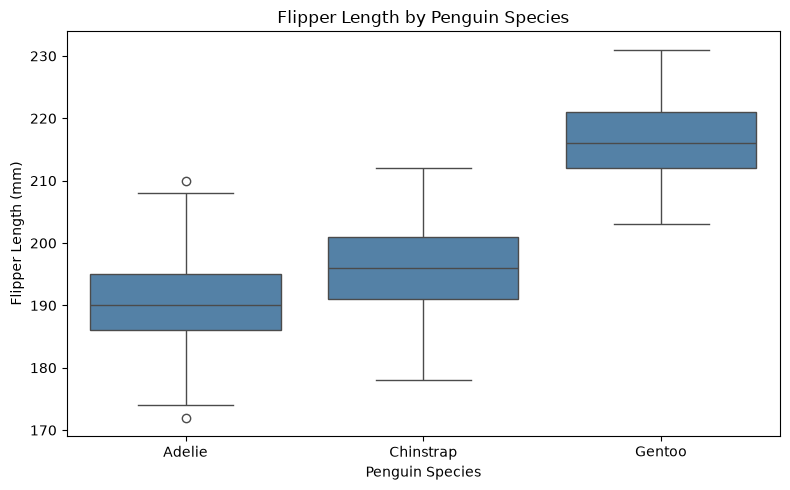

In [46]:
# Order species from shortest to longest median flipper length
flipper_order = (
    flipper_summary
    .sort_values("median_flipper_length")
    .index.tolist()
)

# Create the box plot
fig, ax = plt.subplots(figsize=(8, 5))

sns.boxplot(
    data=flipper_data,
    x="species",
    y="flipper_length_mm",
    order=flipper_order,
    color="steelblue",
    ax=ax
)

ax.set_title("Flipper Length by Penguin Species")
ax.set_xlabel("Penguin Species")
ax.set_ylabel("Flipper Length (mm)")

plt.tight_layout()

# Save the figure
fig.savefig("Lab5_Independent_Plot.png")

plt.show()

In [47]:
Path("Lab5_Independent_Plot.png").exists()

True

## XII. Submission check

Before submitting:

- Add your name and date at the top of the notebook.
- Complete Questions 1-15.
- Restart the kernel and run every cell from top to bottom.
- Confirm that each plot has a clear purpose, title, labels, units, and readable grouping choices.
- Confirm that the final check for `Lab5_Independent_Plot.png` returns `True`.
- Export the completed notebook to HTML and open the HTML to inspect it.
- Submit the completed HTML export and `Lab5_Independent_Plot.png` as directed in Canvas.
